## Download the raw Parquet file

We keep the download step deterministic so the notebook is safe to rerun. The next cell:

- defines the source URL and local file path,
- creates the `data/` directory if needed,
- reuses the Parquet file if it is already present,
- downloads the file only when it is missing.

This is helpful because rerunning the notebook should not create `filename.parquet.1` style duplicates.


In [46]:
from pathlib import Path
from time import time
from urllib.request import urlretrieve

import pandas as pd

DATA_URL = (
    "https://d37ci6vzurychx.cloudfront.net/trip-data/yellow_tripdata_2025-01.parquet"
)
DATA_DIR = Path("../data")
PARQUET_PATH = DATA_DIR / "yellow_tripdata_2025-01.parquet"

DATA_DIR.mkdir(parents=True, exist_ok=True)

if PARQUET_PATH.exists():
    print(f"Reusing existing file: {PARQUET_PATH}")
else:
    print(f"Downloading {DATA_URL}")
    urlretrieve(DATA_URL, PARQUET_PATH)
    print(f"Saved file to {PARQUET_PATH}")

PARQUET_PATH

Reusing existing file: ..\data\yellow_tripdata_2025-01.parquet


WindowsPath('../data/yellow_tripdata_2025-01.parquet')

## Take a look at the data and get an idea of their types and statistics

In [47]:
rides = pd.read_parquet(PARQUET_PATH)
print(f"Loaded {len(rides):,} rows and {len(rides.columns)} columns from {PARQUET_PATH.name}")
rides.head(5)

Loaded 3,475,226 rows and 20 columns from yellow_tripdata_2025-01.parquet


,VendorID,tpep_pickup_datetime,tpep_dropoff_datetime,passenger_count,trip_distance,RatecodeID,store_and_fwd_flag,PULocationID,DOLocationID,payment_type,fare_amount,extra,mta_tax,tip_amount,tolls_amount,improvement_surcharge,total_amount,congestion_surcharge,Airport_fee,cbd_congestion_fee
0,1,2025-01-01 00:18:38,2025-01-01 00:26:59,1.0,1.60,1.0,N,229,237,1,10.0,3.5,0.5,3.00,0.0,1.0,18.00,2.5,0.0,0.0
1,1,2025-01-01 00:32:40,2025-01-01 00:35:13,1.0,0.50,1.0,N,236,237,1,5.1,3.5,0.5,2.02,0.0,1.0,12.12,2.5,0.0,0.0
2,1,2025-01-01 00:44:04,2025-01-01 00:46:01,1.0,0.60,1.0,N,141,141,1,5.1,3.5,0.5,2.00,0.0,1.0,12.10,2.5,0.0,0.0
3,2,2025-01-01 00:14:27,2025-01-01 00:20:01,3.0,0.52,1.0,N,244,244,2,7.2,1.0,0.5,0.00,0.0,1.0,9.70,0.0,0.0,0.0
4,2,2025-01-01 00:21:34,2025-01-01 00:25:06,3.0,0.66,1.0,N,244,116,2,5.8,1.0,0.5,0.00,0.0,1.0,8.30,0.0,0.0,0.0


In [48]:
rides.info()

<class 'pandas.DataFrame'>
RangeIndex: 3475226 entries, 0 to 3475225
Data columns (total 20 columns):
 #   Column                 Dtype         
---  ------                 -----         
 0   VendorID               int32         
 1   tpep_pickup_datetime   datetime64[us]
 2   tpep_dropoff_datetime  datetime64[us]
 3   passenger_count        float64       
 4   trip_distance          float64       
 5   RatecodeID             float64       
 6   store_and_fwd_flag     str           
 7   PULocationID           int32         
 8   DOLocationID           int32         
 9   payment_type           int64         
 10  fare_amount            float64       
 11  extra                  float64       
 12  mta_tax                float64       
 13  tip_amount             float64       
 14  tolls_amount           float64       
 15  improvement_surcharge  float64       
 16  total_amount           float64       
 17  congestion_surcharge   float64       
 18  Airport_fee            float64   

In [49]:
# statistics summary
rides.describe().round(2)

,VendorID,tpep_pickup_datetime,tpep_dropoff_datetime,passenger_count,trip_distance,RatecodeID,PULocationID,DOLocationID,payment_type,fare_amount,extra,mta_tax,tip_amount,tolls_amount,improvement_surcharge,total_amount,congestion_surcharge,Airport_fee,cbd_congestion_fee
count,3475226.00,3475226,3475226,2935077.00,3475226.00,2935077.00,3475226.00,3475226.00,3475226.00,3475226.00,3475226.00,3475226.00,3475226.00,3475226.00,3475226.00,3475226.00,2935077.00,2935077.00,3475226.00
mean,1.79,2025-01-17 11:02:55.910964,2025-01-17 11:17:56.997901,1.30,5.86,2.48,165.19,164.13,1.04,17.08,1.32,0.48,2.96,0.45,0.95,25.61,2.23,0.12,0.48
min,1.00,2024-12-31 20:47:55,2024-12-18 07:52:40,0.00,0.00,1.00,1.00,1.00,0.00,-900.00,-7.50,-0.50,-86.00,-126.94,-1.00,-901.00,-2.50,-1.75,-0.75
25%,2.00,2025-01-10 07:59:01,2025-01-10 08:15:29.500000,1.00,0.98,1.00,132.00,113.00,1.00,8.60,0.00,0.50,0.00,0.00,1.00,15.20,2.50,0.00,0.00
50%,2.00,2025-01-17 15:41:33,2025-01-17 15:59:34,1.00,1.67,1.00,162.00,162.00,1.00,12.11,0.00,0.50,2.45,0.00,1.00,19.95,2.50,0.00,0.75
75%,2.00,2025-01-24 19:34:06,2025-01-24 19:48:31,1.00,3.10,1.00,234.00,234.00,1.00,19.50,2.50,0.50,3.93,0.00,1.00,27.78,2.50,0.00,0.75
max,7.00,2025-02-01 00:00:44,2025-02-01 23:44:11,9.00,276423.57,99.00,265.00,265.00,5.00,863372.12,15.00,10.50,400.00,170.94,1.00,863380.37,2.50,6.75,0.75
std,0.43,NaN,NaN,0.75,564.60,11.63,64.53,69.40,0.70,463.47,1.86,0.14,3.78,2.00,0.28,463.66,0.90,0.47,0.36


## Clean the data and prepare it for feature engineering

In [50]:
# missing values
rides.isna().sum()

VendorID                      0
tpep_pickup_datetime          0
tpep_dropoff_datetime         0
passenger_count          540149
trip_distance                 0
RatecodeID               540149
store_and_fwd_flag       540149
PULocationID                  0
DOLocationID                  0
payment_type                  0
fare_amount                   0
extra                         0
mta_tax                       0
tip_amount                    0
tolls_amount                  0
improvement_surcharge         0
total_amount                  0
congestion_surcharge     540149
Airport_fee              540149
cbd_congestion_fee            0
dtype: int64

In [51]:
# how many out of range of month
first_of_January = pd.Timestamp(year=2025, month=1, day=1)
end_of_January = first_of_January + pd.DateOffset(months=1)

out_of_range = rides[
    (rides["tpep_pickup_datetime"] < first_of_January)
    | (rides["tpep_pickup_datetime"] >= end_of_January)
]
print(len(out_of_range))

22


In [52]:
# remove days out of month range
rides = rides[
    rides["tpep_pickup_datetime"].ge(first_of_January)
    & rides["tpep_pickup_datetime"].le(end_of_January)
].copy()

rides.shape


(3475204, 20)

### Calculate trip duration (the target) based on pickup and dropoff time stamps

In [53]:
SECONDS_PER_MINUTE = 60

rides["trip_duration_minutes"] = (rides["tpep_dropoff_datetime"] - rides["tpep_pickup_datetime"]).dt.total_seconds() / SECONDS_PER_MINUTE

rides["trip_duration_minutes"].head(10)

0     8.350000
1     2.550000
2     1.950000
3     5.566667
4     3.533333
5    20.033333
6     1.466667
7    12.400000
8    19.666667
9     9.566667
Name: trip_duration_minutes, dtype: float64

In [54]:
# trips longer than 6 hours, which is strange
too_long_trips = rides[rides["trip_duration_minutes"] > 6*60]
print(len(too_long_trips))

1203


In [55]:
# trips that are shorter than a minute are also suspicious, not to mention negative values!
too_short_trips = rides[rides["trip_duration_minutes"] < 1]
print(len(too_short_trips))

40111


In [56]:
# remove all of them
rides = rides[ (rides["trip_duration_minutes"] >= 1) ].copy()
rides = rides[ (rides["trip_duration_minutes"] <= 6*60)].copy()
rides.shape


(3433890, 21)

In [57]:
assert(3475204 == 3433890+40111+1203)

In [58]:
rides["trip_duration_minutes"].describe().round(2)

count    3433890.00
mean          14.77
std           11.41
min            1.00
25%            7.42
50%           11.82
75%           18.45
max          359.92
Name: trip_duration_minutes, dtype: float64

## Identifying candidate features for predicting trip duration

### One of the most promising features should be the trip distance. How does it look?

In [59]:
rides["trip_distance"].describe().round(2)

count    3433890.00
mean           5.92
std          567.99
min            0.00
25%            1.00
50%            1.69
75%            3.13
max       276423.57
Name: trip_distance, dtype: float64

In [60]:
# zero distances?
zero_distance_trips = rides[rides["trip_distance"] <= 0]
print(len(zero_distance_trips))

64362


In [61]:
# let's remove trips with zero distance
rides = rides[rides["trip_distance"] > 0].copy()
rides.shape

(3369528, 21)

In [62]:
assert(3369528+64362 == 3433890)

In [63]:
# too long distances?
rides.nlargest(10, "trip_distance")

,VendorID,tpep_pickup_datetime,tpep_dropoff_datetime,passenger_count,trip_distance,RatecodeID,store_and_fwd_flag,PULocationID,DOLocationID,payment_type,...,extra,mta_tax,tip_amount,tolls_amount,improvement_surcharge,total_amount,congestion_surcharge,Airport_fee,cbd_congestion_fee,trip_duration_minutes
3275762,2,2025-01-22 21:04:00,2025-01-22 21:13:00,NaN,276423.57,NaN,NaN,161,170,0,...,0.0,0.5,0.0,0.0,1.0,5.00,NaN,NaN,0.75,9.0
3188501,2,2025-01-19 14:51:00,2025-01-19 14:58:00,NaN,276099.95,NaN,NaN,224,233,0,...,0.0,0.5,0.0,0.0,1.0,13.88,NaN,NaN,0.75,7.0
3240337,2,2025-01-21 09:19:00,2025-01-21 09:45:00,NaN,222167.49,NaN,NaN,52,144,0,...,0.0,0.5,0.0,0.0,1.0,35.94,NaN,NaN,0.75,26.0
3112173,2,2025-01-16 10:47:00,2025-01-16 11:11:00,NaN,206137.99,NaN,NaN,263,48,0,...,0.0,0.5,0.0,0.0,1.0,29.64,NaN,NaN,0.75,24.0
3374854,2,2025-01-26 17:46:00,2025-01-26 17:59:00,NaN,202771.63,NaN,NaN,50,186,0,...,0.0,0.5,0.0,0.0,1.0,14.85,NaN,NaN,0.75,13.0
3081597,2,2025-01-14 19:18:00,2025-01-14 19:36:00,NaN,189687.43,NaN,NaN,246,164,0,...,0.0,0.5,0.0,0.0,1.0,17.45,NaN,NaN,0.75,18.0
3069039,2,2025-01-13 21:11:00,2025-01-13 21:17:00,NaN,181139.99,NaN,NaN,100,90,0,...,0.0,0.5,0.0,0.0,1.0,11.08,NaN,NaN,0.75,6.0
3312563,2,2025-01-24 08:33:00,2025-01-24 08:44:00,NaN,168079.57,NaN,NaN,42,238,0,...,0.0,0.5,0.0,0.0,1.0,4.49,NaN,NaN,0.00,11.0
3195037,2,2025-01-19 18:31:00,2025-01-19 18:58:00,NaN,167452.94,NaN,NaN,247,239,0,...,0.0,0.5,0.0,0.0,1.0,5.45,NaN,NaN,0.00,27.0
3138510,2,2025-01-17 14:25:00,2025-01-17 14:40:00,NaN,164959.95,NaN,NaN,262,239,0,...,0.0,0.5,0.0,0.0,1.0,18.05,NaN,NaN,0.00,15.0


In [64]:
# let's assume a maximum distance for trips within 6 hours as limited above, with an average speed of 60 mph
MAX_DISTANCE = 6*60 # miles

# filter out trips above this limit
rides = rides[rides["trip_distance"] <= MAX_DISTANCE].copy()
rides.shape

(3369410, 21)

### What about the total_amount as a feature candidate?

In [65]:
# there weren't any missing values, were there?
rides["total_amount"].isna().sum()

np.int64(0)

In [66]:
rides["total_amount"].describe().round(2)

count    3369410.00
mean          25.67
std          470.84
min         -901.00
25%           15.39
50%           20.00
75%           27.77
max       863380.37
Name: total_amount, dtype: float64

In [67]:
# negative charges?
print(len(rides[rides["total_amount"] < 0]))

55796


In [68]:
# let's remove these trips too
rides = rides[rides["total_amount"] >= 0].copy()
rides.shape

(3313614, 21)

In [69]:
# the most expensive trips
rides.nlargest(10, "total_amount")

,VendorID,tpep_pickup_datetime,tpep_dropoff_datetime,passenger_count,trip_distance,RatecodeID,store_and_fwd_flag,PULocationID,DOLocationID,payment_type,...,extra,mta_tax,tip_amount,tolls_amount,improvement_surcharge,total_amount,congestion_surcharge,Airport_fee,cbd_congestion_fee,trip_duration_minutes
1780915,1,2025-01-20 12:07:18,2025-01-20 12:12:42,1.0,1.60,1.0,N,138,8,4,...,6.75,0.5,0.00,0.00,1.0,863380.37,0.0,1.75,0.00,5.400000
1832645,2,2025-01-21 05:17:57,2025-01-21 08:19:45,1.0,188.88,4.0,N,247,265,2,...,1.00,0.5,0.00,0.00,1.0,1311.70,0.0,0.00,0.00,181.800000
1346041,2,2025-01-15 19:14:42,2025-01-15 21:46:13,1.0,143.54,4.0,N,132,265,1,...,2.50,0.0,0.00,27.00,1.0,969.05,0.0,1.75,0.00,151.516667
562143,2,2025-01-07 19:12:25,2025-01-07 19:14:04,1.0,0.10,5.0,N,226,226,3,...,0.00,0.0,0.00,0.00,1.0,901.00,0.0,0.00,0.00,1.650000
1126773,1,2025-01-13 17:19:58,2025-01-13 20:07:08,1.0,133.30,5.0,N,132,265,1,...,1.75,0.0,0.00,0.00,1.0,896.50,0.0,1.75,0.00,167.166667
74028,2,2025-01-01 23:13:43,2025-01-02 01:47:38,1.0,132.27,4.0,N,132,265,4,...,1.00,0.0,0.00,35.44,1.0,865.39,0.0,1.75,0.00,153.916667
34810,2,2025-01-01 12:53:37,2025-01-01 15:25:57,1.0,119.66,4.0,N,101,265,2,...,0.00,0.5,0.00,20.32,1.0,794.82,0.0,0.00,0.00,152.333333
1975958,2,2025-01-22 15:09:41,2025-01-22 16:55:52,2.0,83.02,4.0,N,48,265,1,...,0.00,0.0,122.33,14.06,1.0,734.74,0.0,0.00,0.75,106.183333
1160453,2,2025-01-14 02:08:52,2025-01-14 02:10:20,1.0,0.35,5.0,N,230,48,4,...,0.00,0.0,0.00,0.00,1.0,704.25,2.5,0.00,0.75,1.466667
160259,2,2025-01-03 06:30:10,2025-01-03 08:17:18,1.0,111.20,4.0,N,132,265,2,...,0.00,0.0,0.00,29.26,1.0,702.11,0.0,1.75,0.00,107.133333


In [70]:
# the first one seems to be too expensive for its duration, therefore, it will be removed!
rides = rides.drop(index=1780915).reset_index(drop=True)

In [71]:
rides.nlargest(5, "total_amount")

,VendorID,tpep_pickup_datetime,tpep_dropoff_datetime,passenger_count,trip_distance,RatecodeID,store_and_fwd_flag,PULocationID,DOLocationID,payment_type,...,extra,mta_tax,tip_amount,tolls_amount,improvement_surcharge,total_amount,congestion_surcharge,Airport_fee,cbd_congestion_fee,trip_duration_minutes
1764705,2,2025-01-21 05:17:57,2025-01-21 08:19:45,1.0,188.88,4.0,N,247,265,2,...,1.00,0.5,0.0,0.00,1.0,1311.70,0.0,0.00,0.0,181.800000
1295985,2,2025-01-15 19:14:42,2025-01-15 21:46:13,1.0,143.54,4.0,N,132,265,1,...,2.50,0.0,0.0,27.00,1.0,969.05,0.0,1.75,0.0,151.516667
538796,2,2025-01-07 19:12:25,2025-01-07 19:14:04,1.0,0.10,5.0,N,226,226,3,...,0.00,0.0,0.0,0.00,1.0,901.00,0.0,0.00,0.0,1.650000
1083807,1,2025-01-13 17:19:58,2025-01-13 20:07:08,1.0,133.30,5.0,N,132,265,1,...,1.75,0.0,0.0,0.00,1.0,896.50,0.0,1.75,0.0,167.166667
70178,2,2025-01-01 23:13:43,2025-01-02 01:47:38,1.0,132.27,4.0,N,132,265,4,...,1.00,0.0,0.0,35.44,1.0,865.39,0.0,1.75,0.0,153.916667


### Considering the trip route based on the pickup and dropoff locations id's as a categorical feature

In [72]:
rides["trip_route"] = (rides["PULocationID"].astype(str) + "_" + rides["DOLocationID"].astype(str))

## Feature engineering and baseline modelling

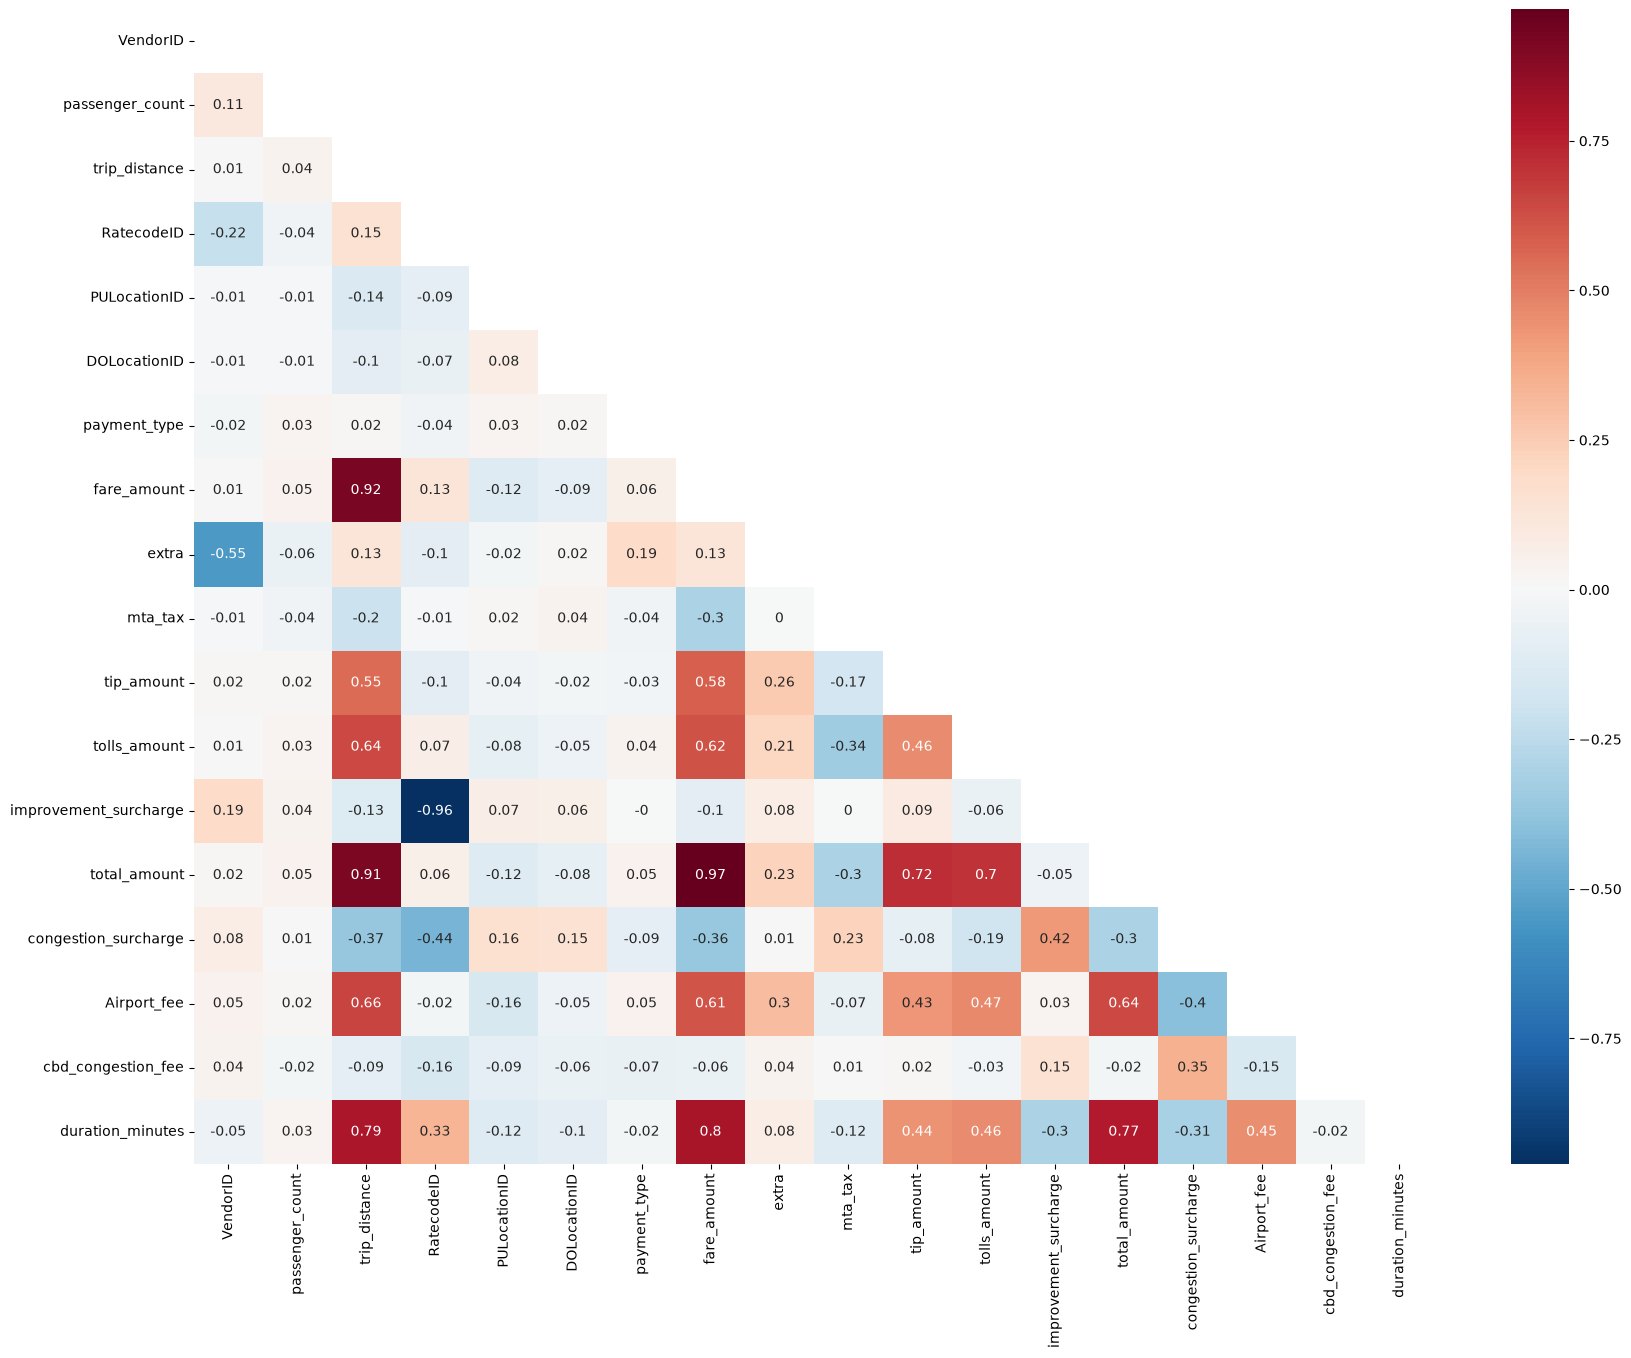

In [73]:
# Heatmap of the Pearson correlation coefficients
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

numeric_data = rides.select_dtypes(include=["number"])
mask = np.triu(numeric_data.corr())
plt.figure(figsize=(20, 15))
ax = sns.heatmap(round(numeric_data.corr(), 2), annot=True, mask=mask, cmap="RdBu_r")

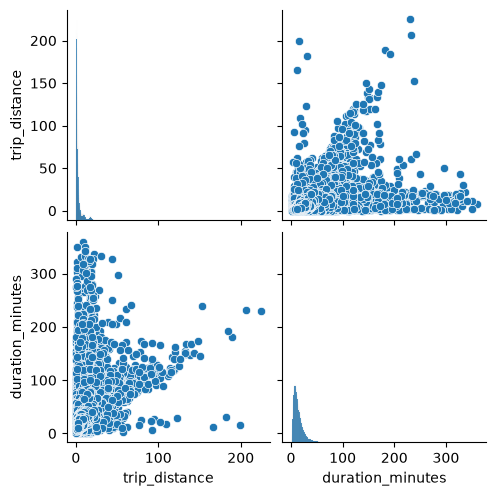

In [74]:
# Plot scatterplots
pair_to_plot = ["trip_distance", "trip_duration_minutes"]
sns.pairplot(rides[pair_to_plot])

So let's concentrate on the following features:

In [75]:
feature_columns = ["trip_distance", "total_amount"] #["trip_distance", "total_amount", "trip_route"]
target_column = "trip_duration_minutes"

X = rides[feature_columns]
y = rides[target_column]

In [76]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.3, random_state=42
)


In [77]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.pipeline import Pipeline


preprocessor = ColumnTransformer(
    transformers=[
        ("route", OneHotEncoder(handle_unknown="ignore"), ["trip_route"]),
    ],
    remainder="passthrough",
)

baseline_pipeline = Pipeline(
    [
        #("preprocessor", preprocessor),
        ("model", RandomForestRegressor(
            n_estimators=100,
            max_depth=15,
            min_samples_leaf=2,
            n_jobs=-1,
            random_state=42)),
    ]
)

baseline_pipeline.fit(X_train, y_train)
predictions = baseline_pipeline.predict(X_test)

### Model evaluation (metrics)

In [78]:
comparison = X_test.copy()
comparison["actual_duration"] = y_test.round(2)
comparison["predicted_duration"] = pd.Series(predictions, index=X_test.index).round(2)
comparison.sort_index()

mae = mean_absolute_error(y_test, predictions)
print(f"MAE: {mae:,.0f}")

mse = mean_squared_error(y_test, predictions)
print(f"MSE: {mse:,.0f}")

rmse = np.sqrt(mse)
print(f"RMSE: {rmse:,.0f}")

r2 = r2_score(y_test, predictions)
print(f"R²: {r2:.3f}")



MAE: 3
MSE: 27
RMSE: 5
R²: 0.796


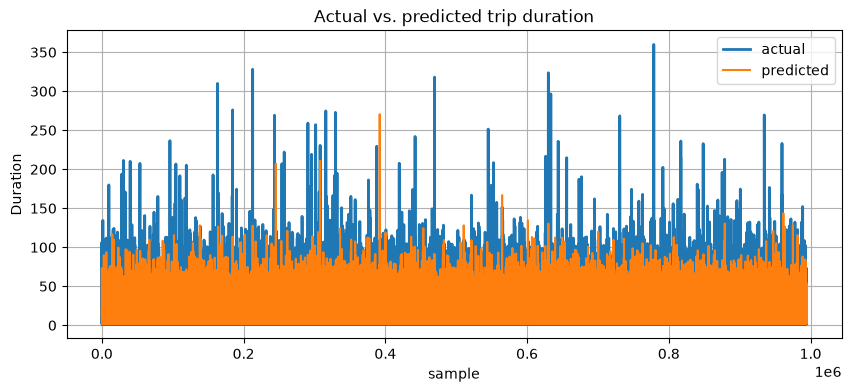

,actual,predicted
0,17.900000,17.558772
1,2.433333,2.522641
2,14.650000,16.830065
3,7.783333,12.608348
4,20.116667,18.248925
5,11.266667,9.272983
6,7.050000,11.898374
7,9.283333,10.011631
8,31.616667,28.921361
9,15.766667,17.301237


In [79]:
# plotting

comparison_df = pd.DataFrame(
    {
        "actual": y_test,
        "predicted": predictions,
    }
).reset_index(drop=True)

plt.figure(figsize=(10, 4))
plt.plot(comparison_df.index, comparison_df["actual"], label="actual", linewidth=2)
plt.plot(
    comparison_df.index,
    comparison_df["predicted"],
    label="predicted",
    linewidth=1.5,
)
plt.title("Actual vs. predicted trip duration")
plt.xlabel("sample")
plt.ylabel("Duration")
plt.legend()
plt.grid(True)
plt.show()

comparison_df.head(10)

## MLFlow

From the repository root, run:

```bash
uv run mlflow server \
  --host 127.0.0.1 \
  --port 5000 \
  --backend-store-uri sqlite:///mlflow.db \
  --default-artifact-root ./mlartifacts \
  --allowed-hosts "localhost:5000,127.0.0.1:5000,host.docker.internal:5000"
  ```

In [80]:
import os
from dotenv import load_dotenv

PROJECT_ROOT = Path.cwd() if (Path.cwd() / ".env").exists() else Path.cwd().parent
load_dotenv(dotenv_path=PROJECT_ROOT / ".env")

MLFLOW_TRACKING_URI = os.getenv("MLFLOW_TRACKING_URI", "http://127.0.0.1:5000")
EXPERIMENT_NAME: str = os.getenv("MLFLOW_EXPERIMENT_NAME", "yellow-taxi-duration")
REGISTERED_MODEL_NAME = os.getenv("MLFLOW_MODEL_NAME", "rfr-ride-duration")
MODEL_ALIAS = os.getenv("MODEL_ALIAS", "production")

print(
    {
        "tracking_uri": MLFLOW_TRACKING_URI,
        "registered_model_name": REGISTERED_MODEL_NAME,
        "model_alias": MODEL_ALIAS,
    }
)

{'tracking_uri': 'http://127.0.0.1:5000', 'registered_model_name': 'rfr-ride-duration', 'model_alias': 'production'}


In [81]:
import mlflow
from mlflow import MlflowClient
from mlflow.exceptions import MlflowException

mlflow.set_tracking_uri(MLFLOW_TRACKING_URI)
mlflow.set_experiment(EXPERIMENT_NAME)

with mlflow.start_run(run_name="Notebook experimentation") as run:
    mlflow.log_param("model_type", "RandomForestRegressor")
    mlflow.log_param("feature_columns", ", ".join(feature_columns))
    mlflow.log_param("random_state", 42)
    mlflow.log_param("train_data_uri", "https://d37ci6vzurychx.cloudfront.net/trip-data/yellow_tripdata_2025-01.parquet")
    mlflow.log_param("test_size", 0.3)
    
    mlflow.log_metric("rmse_minutes", rmse)
    model_info = mlflow.sklearn.log_model(
        sk_model=baseline_pipeline,
        name="baseline model",
        input_example=X_train.head(2),
        skops_trusted_types=["sklearn.tree._tree.Tree"],

    )
    run_id = run.info.run_id

print({"run_id": run_id, "tracking_uri": mlflow.get_tracking_uri()})

2026/11/19 16:47:58 INFO mlflow.tracking.fluent: Experiment with name 'yellow-taxi-duration' does not exist. Creating a new experiment.
2026/11/19 16:48:07 WARNING mlflow.utils.environment: Failed to resolve installed pip version. ``pip`` will be added to conda.yaml environment spec without a version specifier.


🏃 View run Notebook experimentation at: http://127.0.0.1:5000/#/experiments/1/runs/58e6a1181bce4e09bfc4ff542ca0e9eb
🧪 View experiment at: http://127.0.0.1:5000/#/experiments/1
{'run_id': '58e6a1181bce4e09bfc4ff542ca0e9eb', 'tracking_uri': 'http://127.0.0.1:5000'}


In [82]:
client = MlflowClient()

try:
    client.create_registered_model(
        name=REGISTERED_MODEL_NAME,
        tags={"framework": "scikit-learn"},
        description="Demo model for the local FastAPI deployment workflow.",
    )
    print("Created registered model.")
except MlflowException as error:
    # Reuse the model only if it already exists; re-raise any other MLflow error.
    if error.error_code != "RESOURCE_ALREADY_EXISTS":
        raise
    print("Registered model already exists. Reusing it.")

Created registered model.


In [83]:
model_version = client.create_model_version(
    name=REGISTERED_MODEL_NAME,
    source=model_info.model_uri,
    run_id=run_id,
    model_id=model_info.model_id
)

print({"version": model_version.version})

2026/11/19 16:48:09 INFO mlflow.store.model_registry.abstract_store: Waiting up to 300 seconds for model version to finish creation. Model name: rfr-ride-duration, version 1


{'version': '1'}


In [84]:
from datetime import UTC, datetime

client.set_registered_model_alias(
    name=REGISTERED_MODEL_NAME,
    alias=MODEL_ALIAS,
    version=model_version.version,
)

client.update_model_version(
    name=REGISTERED_MODEL_NAME,
    version=model_version.version,
    description=f"Promoted locally on {datetime.now(tz=UTC).date()} for the FastAPI demo.",
)

print({"alias": MODEL_ALIAS, "version": model_version.version})

{'alias': 'production', 'version': '1'}


## Hyperparameter tuning 

In [85]:
# In order to keep the runtime reasonably low for this notebook, 
# the search will take place only on a smaller sample!

from scipy.stats import randint, uniform
from sklearn.model_selection import RandomizedSearchCV

n_tune = min(20_000, len(X_train))
X_tune = X_train.sample(n=n_tune, random_state=42)
y_tune = y_train.loc[X_tune.index]

param_distributions = {
    "model__n_estimators": randint(50, 301),  # less work per fit
    "model__max_features": ["sqrt", "log2", 0.5, 0.8, 1.0],
    "model__max_depth": [None, 10, 20, 40],
    "model__min_samples_split": randint(2, 21),
    "model__min_samples_leaf": randint(1, 11),
    "model__max_samples": uniform(0.6, 0.4),
}

baseline_pipeline.set_params(model__n_jobs=1)

random_search = RandomizedSearchCV(
    estimator=baseline_pipeline,
    param_distributions=param_distributions,
    n_iter=10,
    cv=3,
    scoring="neg_root_mean_squared_error",
    n_jobs=1,
    random_state=42,
)

random_search.fit(X_tune, y_tune)

test_rmse = np.sqrt(
    mean_squared_error(y_test, random_search.best_estimator_.predict(X_test))
)

print("Best parameters:", random_search.best_params_)
print(f"Best CV RMSE: {-random_search.best_score_:.3f}")
print(f"Test RMSE: {test_rmse:.3f}")

Best parameters: {'model__max_depth': 40, 'model__max_features': 0.5, 'model__max_samples': np.float64(0.608233797718321), 'model__min_samples_leaf': 2, 'model__min_samples_split': 13, 'model__n_estimators': 207}
Best CV RMSE: 6.157
Test RMSE: 5.606


In [86]:
# log in MLFLow
with mlflow.start_run(run_name="Notebook experimentation") as run:
    mlflow.log_param("model_type", "RandomForestRegressor")
    mlflow.log_param("feature_columns", ", ".join(feature_columns))
    mlflow.log_metric("rmse_minutes", test_rmse)
    mlflow.log_param("RandomizedSearchCV", "RandomizedSearchCV")
    model_info = mlflow.sklearn.log_model(
        sk_model=random_search.best_estimator_,
        name="model hyperparameter tuned",
        input_example=X_train.head(2),
        skops_trusted_types=["sklearn.tree._tree.Tree"],

    )
    run_id = run.info.run_id

2026/11/19 16:49:08 WARNING mlflow.utils.environment: Failed to resolve installed pip version. ``pip`` will be added to conda.yaml environment spec without a version specifier.


🏃 View run Notebook experimentation at: http://127.0.0.1:5000/#/experiments/1/runs/9f5296f397d740de8a6bb058068f61d4
🧪 View experiment at: http://127.0.0.1:5000/#/experiments/1


In [87]:
try:
    client.create_registered_model(
        name=REGISTERED_MODEL_NAME,
        tags={"framework": "scikit-learn"},
        description="Demo model for the local FastAPI deployment workflow.",
    )
    print("Created registered model.")
except MlflowException as error:
    # Reuse the model only if it already exists; re-raise any other MLflow error.
    if error.error_code != "RESOURCE_ALREADY_EXISTS":
        raise
    print("Registered model already exists. Reusing it.")

Registered model already exists. Reusing it.


In [88]:
model_version = client.create_model_version(
    name=REGISTERED_MODEL_NAME,
    source=model_info.model_uri,
    run_id=run_id,
    model_id=model_info.model_id
)

print({"version": model_version.version})

2026/11/19 16:49:10 INFO mlflow.store.model_registry.abstract_store: Waiting up to 300 seconds for model version to finish creation. Model name: rfr-ride-duration, version 2


{'version': '2'}


In [89]:
## Set the production alias only if this model is better!

versions = client.search_model_versions(filter_string=f"name='{REGISTERED_MODEL_NAME}'")


# Find the version currently carrying the model alias.
production = next(
    (
        client.get_model_version(REGISTERED_MODEL_NAME, v.version)
        for v in versions
        if MODEL_ALIAS in
        client.get_model_version(REGISTERED_MODEL_NAME, v.version).aliases
    ),
    None,
)

if production is None:
    # No current production version: establish the initial alias.
    client.set_registered_model_alias(
    name=REGISTERED_MODEL_NAME,
    alias=MODEL_ALIAS,
    version=model_version.version,
)
else:
    production_score = client.get_run(production.run_id).data.metrics.get("rmse_minutes")
    if production_score is None:
        raise ValueError(f"'rmse_minutes' is missing from production run {production.run_id}")

    if test_rmse < production_score:  # reverse this for lower-is-better metrics
        client.set_registered_model_alias(
            REGISTERED_MODEL_NAME, MODEL_ALIAS, model_version.version
        )

## Inspect Registered Versions

In [90]:
version_table = pd.DataFrame(
    [
        {
            "version": version.version,
            "aliases": ", ".join(
                client.get_model_version(REGISTERED_MODEL_NAME, version.version).aliases
                or []
            ),
            "run_id": version.run_id,
        }
        for version in versions
    ]
)

version_table.sort_values("version", ascending=False).reset_index(drop=True)

,version,aliases,run_id
0,2,,9f5296f397d740de8a6bb058068f61d4
1,1,production,58e6a1181bce4e09bfc4ff542ca0e9eb
